# Practice Notebook 2 (Week 2): Rank-Based Non-Parametric Tests

Advanced Statistics Course, Brain Science, Period 2

This notebook lets you practise the rank-based tests of Week 2: the **Wilcoxon signed-rank test**, the **Mann–Whitney U test** and the **Kruskal–Wallis test**. It combines **paper-and-pencil exercises** (do these by hand first, **do not use Python**) with **Python exercises**.

**How to use this notebook:** every exercise is followed by its solution. For the coding parts, first work in the cell marked `# your answer`, then compare with the solution cell(s) underneath. Try not to scroll ahead.

For the Python exercises you need *numpy*, *pandas*, *scipy* and *matplotlib*.

### Learning Goals
- Rank data correctly, including ties.
- Carry out the Wilcoxon signed-rank test and the Mann–Whitney U test by hand and verify them in Python.
- Compute the Kruskal–Wallis $H$ statistic and interpret an omnibus result.
- See in a simulation when rank tests beat the t-test, and when they lose power.
- Detect a wrongly chosen test in a study description.

## Part 1: Ranking with Ties

**2.1** Eight participants produced the following numbers of intrusion errors in a recall task:

`[12, 15, 15, 9, 20, 15, 9, 30]`

### Tasks (paper and pencil, **do not use Python!**)
a) Assign ranks (smallest value = rank 1). Give tied values the average rank.

b) Check your ranks: what must the sum of all ranks equal for $n$ observations?

### Answer 2.1

**a)** Sorted: 9, 9, 12, 15, 15, 15, 20, 30

- The two 9s occupy ranks 1 and 2, so both get $(1+2)/2 = 1.5$.
- 12 gets rank 3.
- The three 15s occupy ranks 4, 5 and 6, so all get $(4+5+6)/3 = 5$.
- 20 gets rank 7; 30 gets rank 8.

In the original order: `[3, 5, 5, 1.5, 7, 5, 1.5, 8]`

**b)** The ranks $1, \dots, n$ always sum to $\frac{n(n+1)}{2} = \frac{8 \cdot 9}{2} = 36$. Check: $3+5+5+1.5+7+5+1.5+8 = 36$. ✓ Averaging tied ranks does not change the sum.

Verify your ranks with `scipy.stats.rankdata` and check the rank sum.

In [ ]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt

errors = np.array([12, 15, 15, 9, 20, 15, 9, 30])

# your answer

### Solution 2.1

In [2]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt

errors = np.array([12, 15, 15, 9, 20, 15, 9, 30])
ranks = stats.rankdata(errors)          # default method='average' handles ties
n = len(errors)

print("Values:", errors)
print("Ranks: ", ranks)
print(f"Sum of ranks = {ranks.sum()}, n(n+1)/2 = {n * (n + 1) / 2}")

Values: [12 15 15  9 20 15  9 30]
Ranks:  [3.  5.  5.  1.5 7.  5.  1.5 8. ]
Sum of ranks = 36.0, n(n+1)/2 = 36.0


## Part 2: Wilcoxon Signed-Rank Test

**2.2** Nine participants completed a working-memory span task before and after four weeks of training:

| Participant | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 |
|-------------|---|---|---|---|---|---|---|---|---|
| Pre         | 5 | 6 | 7 | 4 | 6 | 5 | 3 | 7 | 5 |
| Post        | 8 | 7 | 7 | 8 | 5 | 8 | 9 | 5 | 8 |

Use the Wilcoxon signed-rank test (two-tailed, $\alpha = 0.05$) to test whether span changed.

Critical values $W_{crit}$ (two-tailed, $\alpha = 0.05$):

| n | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|----|
| $W_{crit}$ | 0 | 2 | 3 | 5 | 8 |

### Tasks (paper and pencil, **do not use Python!**)
a) State $H_0$ and $H_1$.

b) Compute the differences $d = \text{post} - \text{pre}$. What happens to participant 3?

c) Rank the absolute differences (ties get the average rank), reattach the signs, and compute $W^+$, $W^-$ and $W$.

d) Decide, and formulate the conclusion.

e) Six of eight participants with a non-zero change improved. Why is the result still not significant?

### Answer 2.2

**a)** $H_0$: the median difference (post − pre) is 0. $H_1$: the median difference is not 0.

**b)** $d = +3, +1, 0, +4, -1, +3, +6, -2, +3$. Participant 3 has $d = 0$ and is **dropped**, so $n = 8$.

**c)** Absolute differences sorted: 1, 1, 2, 3, 3, 3, 4, 6

| $\lvert d \rvert$ | 1 | 1 | 2 | 3 | 3 | 3 | 4 | 6 |
|---|---|---|---|---|---|---|---|---|
| Rank | 1.5 | 1.5 | 3 | 5 | 5 | 5 | 7 | 8 |
| Sign | + (P2) | − (P5) | − (P8) | + | + | + | + | + |

- $W^+ = 1.5 + 5 + 5 + 5 + 7 + 8 = 31.5$
- $W^- = 1.5 + 3 = 4.5$
- Check: $W^+ + W^- = 36 = \frac{8 \cdot 9}{2}$ ✓
- $W = \min(W^+, W^-) = 4.5$

**d)** $W_{crit}(n = 8) = 3$. Since $4.5 > 3$, we **fail to reject $H_0$**. There is no significant change in working-memory span at $\alpha = .05$.

**e)** With only 8 informative pairs, the null distribution of $W$ is wide. Only a very lopsided rank pattern ($W \le 3$) is extreme enough. The two decreases occupy ranks 1.5 and 3, and that is already enough to stay above the critical value. Small $n$ means low power: the result is "not enough evidence", not "no effect".

**2.3** Implement the Wilcoxon signed-rank test in Python.

1. Write a function `wilcoxon_by_hand(x, y)` that returns $W^+$, $W^-$, $W$ and the number of non-zero pairs $n$. Use `stats.rankdata` for the ranks.
2. Apply it to the training data from **2.2** and to the lecture example with differences $d = +5, -2, +5, -2, +5, +4, -2$ (lecture result: $W = 6$). Tip: for the lecture example, pass the differences as `x` and an array of zeros as `y`.
3. Compare with `stats.wilcoxon(post, pre)` and with the paired t-test `stats.ttest_rel(post, pre)`.

In [ ]:
pre = np.array([5, 6, 7, 4, 6, 5, 3, 7, 5])
post = np.array([8, 7, 7, 8, 5, 8, 9, 5, 8])
lecture_d = np.array([5, -2, 5, -2, 5, 4, -2])

def wilcoxon_by_hand(x, y):
    # your answer
    pass

# Apply to both data sets and compare with scipy
# your answer

### Solution 2.3

In [4]:
pre = np.array([5, 6, 7, 4, 6, 5, 3, 7, 5])
post = np.array([8, 7, 7, 8, 5, 8, 9, 5, 8])
lecture_d = np.array([5, -2, 5, -2, 5, 4, -2])

def wilcoxon_by_hand(x, y):
    d = np.asarray(x) - np.asarray(y)
    d = d[d != 0]                          # 1. drop zero differences
    ranks = stats.rankdata(np.abs(d))      # 2. rank |d|, ties -> average rank
    w_plus = ranks[d > 0].sum()            # 3. reattach signs
    w_minus = ranks[d < 0].sum()
    return w_plus, w_minus, min(w_plus, w_minus), len(d)   # 4. W = min

for name, x, y in [("Training data", post, pre),
                   ("Lecture example", lecture_d, np.zeros_like(lecture_d))]:
    wp, wm, w, n = wilcoxon_by_hand(x, y)
    print(f"{name}: W+ = {wp}, W- = {wm}, W = {w}, n = {n}")

res_w = stats.wilcoxon(post, pre)
res_t = stats.ttest_rel(post, pre)
print(f"\nscipy Wilcoxon (training): W = {res_w.statistic}, p = {res_w.pvalue:.4f}")
print(f"Paired t-test (training):  t = {res_t.statistic:.2f}, p = {res_t.pvalue:.4f}")

Training data: W+ = 31.5, W- = 4.5, W = 4.5, n = 8
Lecture example: W+ = 22.0, W- = 6.0, W = 6.0, n = 7

scipy Wilcoxon (training): W = 4.5, p = 0.0547
Paired t-test (training):  t = 2.20, p = 0.0586


- The function reproduces $W = 4.5$ for the training data and $W = 6$ for the lecture example. For a two-sided test `stats.wilcoxon` also reports $W = \min(W^+, W^-)$, and it drops zero differences by default (`zero_method="wilcox"`).
- $p \approx .055 > .05$, consistent with the decision by critical value.
- The paired t-test gives a similar p-value here. Both tests are borderline because of the small sample, not because of the choice between them.

## Part 3: Mann–Whitney U Test

**2.4** Pain ratings (0–10, ordinal) were collected from 5 patients with chronic migraine and 6 healthy controls after the same heat stimulus:

- Migraine (group 1): `[7, 9, 6, 8, 10]`
- Controls (group 2): `[3, 5, 6, 2, 4, 7]`

The U statistic is computed from the rank sums: $U_1 = R_1 - \frac{n_1(n_1+1)}{2}$, $U_2 = R_2 - \frac{n_2(n_2+1)}{2}$, and $U = \min(U_1, U_2)$. Reject $H_0$ if $U \le U_{crit}$. For $n_1 = 5$, $n_2 = 6$ (two-tailed, $\alpha = 0.05$): $U_{crit} = 3$.

### Tasks (paper and pencil, **do not use Python!**)
a) State $H_0$.

b) Pool and rank all 11 observations (ties get the average rank).

c) Compute $R_1$, $R_2$, $U_1$, $U_2$ and check that $U_1 + U_2 = n_1 n_2$.

d) Decide and formulate the conclusion.

e) Why is a Mann–Whitney U test more appropriate here than an independent t-test?

### Answer 2.4

**a)** $H_0$: both groups come from the same distribution (no difference in median pain rating).

**b)** Pooled and sorted: 2, 3, 4, 5, 6, 6, 7, 7, 8, 9, 10

| Value | 2 | 3 | 4 | 5 | 6 | 6 | 7 | 7 | 8 | 9 | 10 |
|-------|---|---|---|---|---|---|---|---|---|---|----|
| Group | C | C | C | C | M | C | M | C | M | M | M |
| Rank  | 1 | 2 | 3 | 4 | 5.5 | 5.5 | 7.5 | 7.5 | 9 | 10 | 11 |

**c)**
- $R_1$ (migraine) $= 5.5 + 7.5 + 9 + 10 + 11 = 43$
- $R_2$ (controls) $= 1 + 2 + 3 + 4 + 5.5 + 7.5 = 23$ (check: $43 + 23 = 66 = \frac{11 \cdot 12}{2}$ ✓)
- $U_1 = 43 - \frac{5 \cdot 6}{2} = 28$, $U_2 = 23 - \frac{6 \cdot 7}{2} = 2$
- $U_1 + U_2 = 30 = 5 \cdot 6$ ✓, so $U = 2$

**d)** $U = 2 \le U_{crit} = 3$, so we **reject $H_0$**. Migraine patients tend to give higher pain ratings than controls.

**e)** Pain ratings are **ordinal** (the distance between 2 and 3 is not necessarily the same as between 8 and 9), the groups are tiny, and normality cannot be checked. Mann–Whitney only uses the order of the values.

**2.5** Verify **2.4** in Python.

1. Compute the ranks, rank sums and $U_1$, $U_2$ with `stats.rankdata`.
2. Run `stats.mannwhitneyu(migraine, controls, alternative="two-sided")`. Which of your two U values does scipy report?
3. Compute $U_1 / (n_1 n_2)$. This is the probability that a randomly chosen migraine patient gives a higher rating than a randomly chosen control (ties count half). Why is this a useful addition to the p-value?

In [ ]:
migraine = np.array([7, 9, 6, 8, 10])
controls = np.array([3, 5, 6, 2, 4, 7])

# your answer

### Solution 2.5

In [6]:
migraine = np.array([7, 9, 6, 8, 10])
controls = np.array([3, 5, 6, 2, 4, 7])
n1, n2 = len(migraine), len(controls)

# 1. Ranks, rank sums and U
ranks = stats.rankdata(np.concatenate([migraine, controls]))
R1, R2 = ranks[:n1].sum(), ranks[n1:].sum()
U1 = R1 - n1 * (n1 + 1) / 2
U2 = R2 - n2 * (n2 + 1) / 2
print(f"R1 = {R1}, R2 = {R2}, U1 = {U1}, U2 = {U2}, U1 + U2 = {U1 + U2} (n1*n2 = {n1 * n2})")

# 2. scipy
res = stats.mannwhitneyu(migraine, controls, alternative="two-sided")
print(f"scipy: U = {res.statistic}, p = {res.pvalue:.4f}")

# 3. Probability of superiority
print(f"P(random migraine rating > random control rating) = {U1 / (n1 * n2):.2f}")

R1 = 43.0, R2 = 23.0, U1 = 28.0, U2 = 2.0, U1 + U2 = 30.0 (n1*n2 = 30)
scipy: U = 28.0, p = 0.0219
P(random migraine rating > random control rating) = 0.93


- scipy reports $U_1$, the U statistic of the **first** sample (28), not $\min(U_1, U_2)$. The p-value is the same either way, because $U_1$ and $U_2$ carry the same information.
- $p \approx .022 < .05$: consistent with the hand calculation.
- $U_1/(n_1 n_2) = 0.93$ tells us *how big* the difference is: in 93 % of all patient–control pairs the patient rated higher. Rank tests are often criticised for saying little about the magnitude of a difference, and this quantity partly fixes that.

## Part 4: Kruskal–Wallis Test

**2.6** Reaction times (ms) in a Stroop task were measured in three independent groups (n = 6 each). Reaction times are typically right-skewed.

- Healthy: `[412, 398, 455, 430, 389, 470]`
- MCI (mild cognitive impairment): `[468, 502, 445, 530, 489, 610]`
- AD (Alzheimer's disease): `[560, 515, 640, 598, 720, 575]`

Tasks:
1. Rank all 18 observations together and compute the rank sum $R_i$ of each group.
2. Compute $H = \frac{12}{N(N+1)} \sum_i \frac{R_i^2}{n_i} - 3(N+1)$, where $N$ is the total sample size.
3. Compare $H$ with the $\chi^2$ distribution with $df = k - 1$ (critical value and p-value).
4. Verify with `stats.kruskal`.
5. The test is significant. Can you conclude that all three groups differ from each other?

In [ ]:
healthy = np.array([412, 398, 455, 430, 389, 470])
mci = np.array([468, 502, 445, 530, 489, 610])
ad = np.array([560, 515, 640, 598, 720, 575])

# your answer

### Solution 2.6

In [8]:
healthy = np.array([412, 398, 455, 430, 389, 470])
mci = np.array([468, 502, 445, 530, 489, 610])
ad = np.array([560, 515, 640, 598, 720, 575])
groups = {"Healthy": healthy, "MCI": mci, "AD": ad}

# 1. Rank everything together, then sum ranks within groups
all_data = np.concatenate(list(groups.values()))
ranks = stats.rankdata(all_data)
N, k = len(all_data), len(groups)

start, rank_sums = 0, {}
for name, g in groups.items():
    rank_sums[name] = float(ranks[start:start + len(g)].sum())
    start += len(g)
print("Rank sums:", rank_sums)

# 2. H statistic
H = 12 / (N * (N + 1)) * sum(R ** 2 / len(groups[name]) for name, R in rank_sums.items()) - 3 * (N + 1)

# 3. Compare with chi-square(k - 1)
crit = stats.chi2.ppf(0.95, k - 1)
p = stats.chi2.sf(H, k - 1)
print(f"H = {H:.2f}, df = {k - 1}, critical value = {crit:.2f}, p = {p:.4f}")

# 4. scipy
res = stats.kruskal(healthy, mci, ad)
print(f"scipy: H = {res.statistic:.2f}, p = {res.pvalue:.4f}")

Rank sums: {'Healthy': 24.0, 'MCI': 59.0, 'AD': 88.0}
H = 12.01, df = 2, critical value = 5.99, p = 0.0025
scipy: H = 12.01, p = 0.0025


Healthy vs MCI: p = 0.0152, Bonferroni-adjusted p = 0.0455
Healthy vs AD: p = 0.0022, Bonferroni-adjusted p = 0.0065
MCI vs AD: p = 0.0411, Bonferroni-adjusted p = 0.1234


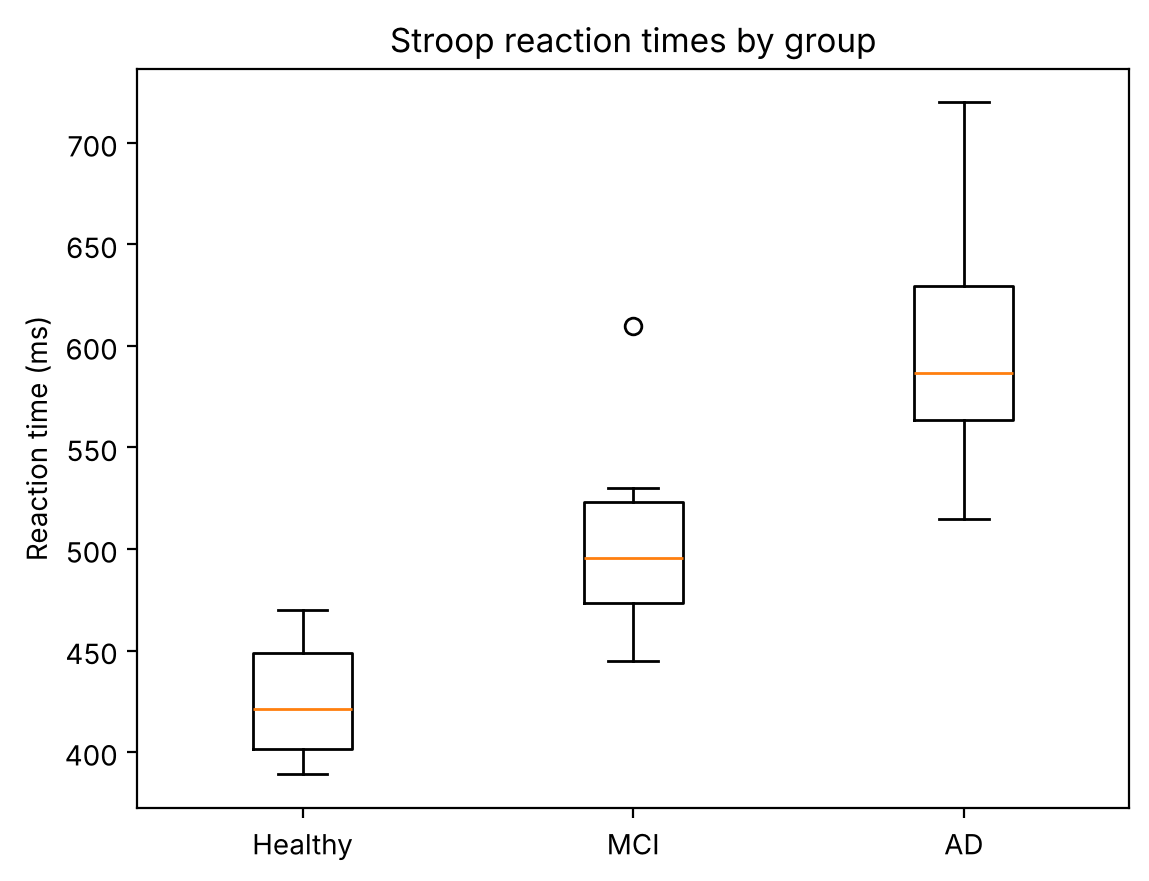

In [9]:
# 5. Follow-up: pairwise Mann-Whitney tests with Bonferroni correction (3 comparisons)
pairs = [("Healthy", "MCI"), ("Healthy", "AD"), ("MCI", "AD")]
for g1, g2 in pairs:
    p_pair = stats.mannwhitneyu(groups[g1], groups[g2], alternative="two-sided").pvalue
    print(f"{g1} vs {g2}: p = {p_pair:.4f}, Bonferroni-adjusted p = {min(1, 3 * p_pair):.4f}")

plt.boxplot(list(groups.values()))
plt.xticks([1, 2, 3], list(groups.keys()))
plt.ylabel("Reaction time (ms)")
plt.title("Stroop reaction times by group")
plt.show()

- $H \approx 12.0 > 5.99$ ($df = 2$), $p \approx .0025$, so **reject $H_0$** (all groups have the same median). There are no ties, so the hand formula and scipy agree exactly (scipy also applies a tie correction when needed).
- **No**, Kruskal–Wallis is an **omnibus** test: it only says that *at least one* group differs. Pairwise follow-up tests (for example Mann–Whitney with a correction for multiple comparisons) show which groups differ. Here Healthy vs. AD and Healthy vs. MCI survive the Bonferroni correction (Healthy vs. MCI only just), but MCI vs. AD does not ($p_{adj} \approx .12$).

## Part 5: Power of Rank Tests vs. the t-Test

**2.7** Rank tests make fewer assumptions, but are they always the better choice? Estimate by simulation the **power** (proportion of significant results at $\alpha = 0.05$) of the independent t-test and the Mann–Whitney U test, with $n = 10$ per group and 2,000 simulated studies per scenario:

- **Scenario A (normal):** group 1 ~ $N(0, 1)$, group 2 ~ $N(1, 1)$.
- **Scenario B (skewed):** group 1 ~ LogNormal($\mu=0, \sigma=1$), group 2 = LogNormal($\mu=0, \sigma=1$) + 1.
- **Scenario C (outliers):** as scenario A, but each observation has a 10 % chance of being replaced by a draw from $N(0, 10)$.

Use `rng = np.random.default_rng(2026)`. Which test wins in which scenario, and why?

In [ ]:
rng = np.random.default_rng(2026)
n, n_sim, alpha = 10, 2000, 0.05

def power(sample_g1, sample_g2):
    # sample_g1, sample_g2: functions that return one simulated group
    # your answer
    pass

# Define the three scenarios and print the power of both tests
# your answer

### Solution 2.7

In [11]:
rng = np.random.default_rng(2026)
n, n_sim, alpha = 10, 2000, 0.05

def power(sample_g1, sample_g2):
    hits_t, hits_u = 0, 0
    for _ in range(n_sim):
        g1, g2 = sample_g1(), sample_g2()
        hits_t += stats.ttest_ind(g1, g2).pvalue < alpha
        hits_u += stats.mannwhitneyu(g1, g2, alternative="two-sided").pvalue < alpha
    return hits_t / n_sim, hits_u / n_sim

def contaminate(x):
    outlier = rng.random(len(x)) < 0.10
    x[outlier] = rng.normal(0, 10, outlier.sum())
    return x

scenarios = {
    "A: normal": (lambda: rng.normal(0, 1, n), lambda: rng.normal(1, 1, n)),
    "B: skewed": (lambda: rng.lognormal(0, 1, n), lambda: rng.lognormal(0, 1, n) + 1),
    "C: outliers": (lambda: contaminate(rng.normal(0, 1, n)), lambda: contaminate(rng.normal(1, 1, n))),
}

results = {name: power(*funcs) for name, funcs in scenarios.items()}
print(pd.DataFrame(results, index=["t-test", "Mann-Whitney"]).T.round(3))

             t-test  Mann-Whitney
A: normal     0.554         0.514
B: skewed     0.316         0.505
C: outliers   0.208         0.360


- **Scenario A (normal):** the t-test is slightly more powerful. When the parametric assumptions hold, ranks throw away some information (the exact distances between values).
- **Scenarios B and C (skewed / outliers):** Mann–Whitney is clearly more powerful. A few extreme values inflate the variance and pull the mean, which hurts the t-test. Ranks are bounded, so one outlier cannot dominate.
- **Take-home:** "non-parametric = safer" is not the full story. If the assumptions hold, the parametric test is the better tool. If they are clearly violated, the rank test can be both more valid *and* more powerful.

## Part 6: Spot the Wrong Test

**2.8** For each study, decide whether the chosen test is appropriate. If not, explain what is wrong and name a better test.

**A.** 12 children with ADHD and 12 controls complete an attention task with skewed scores. The researcher uses a Wilcoxon signed-rank test.

**B.** 15 patients rate their anxiety (ordinal scale) before and after a mindfulness course. The researcher uses a Mann–Whitney U test on the pre- and post-scores.

**C.** Sleep latency (strongly skewed) is compared between placebo and three doses of a hypnotic. The researcher runs all 6 pairwise Mann–Whitney tests at $\alpha = 0.05$ and reports every significant pair.

**D.** EEG amplitudes are approximately normal with equal variances in two groups of n = 200 each. The researcher uses a Mann–Whitney U test "to be safe".

### Answer 2.8

**A. Wrong.** The groups are **independent**, but the Wilcoxon signed-rank test is for **paired** data (it needs one difference per pair, and there are no pairs here). Use the **Mann–Whitney U test**.

**B. Wrong.** Pre and post scores come from the **same** patients, so the samples are **paired**. Mann–Whitney ignores the pairing, so between-person variability masks the within-person change and power is lost. Use the **Wilcoxon signed-rank test** on the paired differences.

**C. Problematic.** Six tests at $\alpha = .05$ inflate the overall Type I error rate. With more than two independent groups, first run the omnibus **Kruskal–Wallis test**, and only follow up significant results with pairwise tests corrected for multiple comparisons.

**D. Valid but not optimal.** The test is not wrong, but the parametric assumptions clearly hold (and n is large). The **independent t-test** is more powerful here, and it directly describes the size of the mean difference. Checking assumptions should guide the choice, not a reflex to "be safe".

## Conceptual Questions

1. In **2.2**, why do we drop pairs with zero difference instead of giving them rank 0 or splitting them between $W^+$ and $W^-$?
2. A colleague says: "The Wilcoxon signed-rank test makes no assumptions." Is this correct? What does it assume?
3. In **2.4**, suppose the highest migraine rating had been 100 instead of 10 (a typo). What happens to the Mann–Whitney result? What would happen to a t-test?
4. Why is the $\chi^2$ distribution used to evaluate the Kruskal–Wallis $H$ statistic?
5. When the Mann–Whitney test is significant, can you always conclude that the **medians** differ?

### Answers

1. A zero difference carries **no information about the direction** of change. Under the procedure from the lecture these pairs are removed, which reduces the effective sample size $n$ (and therefore the critical value you look up).

2. **Not correct.** It is distribution-free (no normality), but it still assumes **paired observations** (and that the pairs are independent of each other), and **differences that are symmetric around the median**. In addition, the data must be at least ordinal, so that differences can be ranked.

3. **Nothing changes** for Mann–Whitney: 100 is still the largest value, so it still gets rank 11, and $U$ and $p$ stay identical. For a t-test, the mean and variance of the migraine group would explode. The variance inflation would likely make the t-test *less* significant despite the larger mean difference. This is the robustness of ranks to outliers.

4. Under $H_0$ (and for not-too-small groups), $H$ is approximately $\chi^2$-distributed with $k - 1$ degrees of freedom. It behaves like a sum of squared standardised deviations of the group mean ranks from the overall mean rank, which is the same structure as the $\chi^2$ statistic. Large $H$ means the mean ranks differ more than expected by chance.

5. **Only if the two distributions have a similar shape** (they differ only by a shift). In general, a significant result means that values in one group *tend to be larger* than in the other (stochastic dominance). Two groups with the same median but different spreads or skews can also produce a significant result.